<table>
    <tr>
        <td colspan=2><strong>International University of La Rioja (UNIR)</strong></td>
    </tr>
    <tr>
        <td colspan=2><strong>Master's Degree in Mathematical Engineering and Computing</strong></td>
    </tr>
    <tr>
        <td>Master's thesis submitted by:</td>
        <td><strong>Andrés Benavides, Diego Salamanca, Yeferson Salamanca.</strong></td>
    </tr>
    <tr>
        <td>Supervisor:</td>
        <td>PhD. Juan Francisco Martínez Cerda</td>
    </tr>
</table>


---


# 06 - Test results analysis

This notebook **evaluates the trained LSTM classifier** (from `05_lstm_model.ipynb`) on the held-out **test split**, breaks down results by class and ticker, and **aligns predicted BUY / HOLD / SELL signals with each ticker's price** so the model's recommendations can be inspected visually. It is purely an analysis notebook: it loads existing artifacts and produces figures and tables (no new files are written).

**Inputs**
- `data/models/lstm_trend_classifier.keras` - the trained model (filename resolved from configuration).
- `data/datasets/test/X.npy`, `.../y.npy` - scaled test sequences `(n_samples, window_size, n_features)` and integer labels (written by notebook 03).
- `data/datasets/test/ids.npy`, `.../dates.npy` - ticker symbol and as-of date per sample, used to associate pooled predictions with a specific stock and trading day.
- `data/datasets/feature_metadata.json` - class mapping, ordered class names, and active label scheme (so plots/reports remain consistent with how the data and model were built).
- `metadata/model_config.json` - resolved configuration (e.g. `batch_size`, `model_filename`, paths).
- `data/processed/merged_processed_data.csv` - `<TICKER>_Adj Close` prices, joined to the signals for the price alignment plot.
- `src/signal_plot.py` - shared styling / plotting helpers (reloaded on each run so changes take effect without restarting the kernel).

**Outputs**
- Inline only: confusion matrices, classification reports, class-count and per-ticker accuracy bar charts, a latest-recommendations table, and per-ticker signal-versus-price plots. Nothing is saved to disk.

**Sections**
1. Imports and paths.
2. Load the model, test `X` / `y` / `dates` / `ids` arrays, and `feature_metadata.json` (recovering class names and the label scheme).
3. Test set evaluation - loss and accuracy on the held-out split, plus predicted class probabilities, predicted labels, and confidence.
4. Prediction analysis across the full test set (all tickers pooled) - confusion matrix (counts + row-normalized), classification report, and true-versus-predicted class-count bars.
5. Per-ticker analysis - per-ticker accuracy bar chart versus overall accuracy, and a table of BUY / HOLD / SELL recommendations from each ticker's latest test window.
6. Test analysis for a specific ticker - configurable `TICKER` and optional `DATE_START` / `DATE_END` window.
7. Align signals with price - filter to the selected ticker, map predicted codes to class names, and join the ticker's `Adj Close` on each sample's decision date (the last day of its window).
8. Signal alignment plot - draw the price line with predicted signals overlaid, colored by class.

**Parameters (section 6)**
- `TICKER` - any sector ticker present in the test set (e.g. `"AAPL"`).
- `DATE_START` / `DATE_END` - `None` for the full test range, or strings such as `"2026-01-01"` / `"2026-05-14"` to zoom in.

## 1. Imports and paths

In [1]:
import importlib
import json
import logging
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    datefmt="%H:%M:%S",
)
logger = logging.getLogger("signal_alignment")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CONFIG_PATH = PROJECT_ROOT / "metadata" / "model_config.json"
DATASET_DIR = PROJECT_ROOT / "data" / "datasets"
MODEL_DIR = PROJECT_ROOT / "data" / "models"
PRICE_CSV = PROJECT_ROOT / "data" / "processed" / "merged_processed_data.csv"

# Styling and plotting live in src/signal_plot.py; reload so edits there are
# picked up without restarting the kernel.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import signal_plot as sp

importlib.reload(sp)

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"CONFIG_PATH   : {CONFIG_PATH}")
print(f"DATASET_DIR  : {DATASET_DIR}")
print(f"MODEL_DIR    : {MODEL_DIR}")
print(f"PRICE_CSV    : {PRICE_CSV}")

PROJECT_ROOT : c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect
CONFIG_PATH   : c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect\metadata\model_config.json
DATASET_DIR  : c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect\data\datasets
MODEL_DIR    : c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect\data\models
PRICE_CSV    : c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect\data\processed\merged_processed_data.csv


## 2. Load the model, test arrays, and metadata

Load the trained model plus the test `X` / `y` / `dates` / `ids` arrays and the `feature_metadata.json` written by notebook 03. From the metadata, we recover the ordered class names and the active label scheme so the plot remains consistent with how the data and model were built.

In [2]:
if CONFIG_PATH.exists():
    with CONFIG_PATH.open("r", encoding="utf-8") as f:
        cfg = json.load(f)
    logger.info("Loaded config from %s", CONFIG_PATH)
else:
    cfg = {}
    logger.warning("No config at %s - using built-in defaults", CONFIG_PATH)
    
META_PATH = DATASET_DIR / "feature_metadata.json"
if not META_PATH.exists():
    raise FileNotFoundError(f"Missing {META_PATH}. Run 04_preprocess_data.ipynb first.")
with META_PATH.open("r", encoding="utf-8") as f:
    feature_metadata = json.load(f)

MODEL_PATH = MODEL_DIR / "lstm_trend_classifier.keras"
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Missing {MODEL_PATH}. Run 05_lstm_model.ipynb first.")
model = keras.models.load_model(MODEL_PATH)

X_test = np.load(DATASET_DIR / "test" / "X.npy")
y_test = np.load(DATASET_DIR / "test" / "y.npy")
test_dates = np.load(DATASET_DIR / "test" / "dates.npy", allow_pickle=True)
test_ids = np.load(DATASET_DIR / "test" / "ids.npy", allow_pickle=True)
assert len(X_test) == len(y_test) == len(test_dates) == len(test_ids), "test arrays length mismatch"

print(f"Test samples : {len(y_test)}  | tickers: {len(np.unique(test_ids))}")
print(f"Date range   : {pd.to_datetime(test_dates).min().date()} -> {pd.to_datetime(test_dates).max().date()}")

CLASS_MAP = {k: int(v) for k, v in feature_metadata["class_mapping"].items()}
# Class names ordered by their integer code (index 0..n-1).
CLASS_NAMES = [name for name, _ in sorted(CLASS_MAP.items(), key=lambda kv: kv[1])]
N_CLASSES = len(CLASS_NAMES)
LABEL_SCHEME = feature_metadata.get("label_scheme")
ORDERED_CLASSES = feature_metadata.get("ordered_classes")

print(f"Label scheme : {LABEL_SCHEME}")
print(f"Class names  : {CLASS_NAMES}")

12:09:08 | INFO | Loaded config from c:\Users\asusadmin\Documents\ChatGPT\Translate_proyect\metadata\model_config.json


Test samples : 4600  | tickers: 25
Date range   : 2025-08-21 -> 2026-05-14
Label scheme : 5class
Class names  : ['SELL_100%', 'SELL_50%', 'HOLD', 'BUY_500USD', 'BUY_1000USD']


## 3. Test set evaluation

Loss and accuracy on the held-out test split (data the model never saw during training or early-stopping selection).

In [3]:
test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=int(cfg["batch_size"]), verbose=0)

print("=" * 50)
print("TEST SET EVALUATION")
print("=" * 50)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}")

# Predict on Test data
y_prob = model.predict(X_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
confidence = y_prob.max(axis=1)

TEST SET EVALUATION
Test loss     : 1.4472
Test accuracy : 0.3607


## 4. Prediction analysis across the full test set

How the model predicts labels across the full test set (all sector tickers pooled):
- **Confusion matrix** - heatmaps of raw counts and row-normalized counts (by true class).
- **Classification report** - precision / recall / F1 / support per class.
- **Class-count bars** - true versus predicted counts per class, to detect systematic over/underprediction of any label.

CLASSIFICATION REPORT (test set)
              precision    recall  f1-score   support

   SELL_100%     0.0268    0.1522    0.0456        46
    SELL_50%     0.0748    0.3432    0.1229       303
        HOLD     0.8358    0.3931    0.5347      3523
  BUY_500USD     0.1423    0.2024    0.1671       588
 BUY_1000USD     0.0965    0.3143    0.1477       140

    accuracy                         0.3607      4600
   macro avg     0.2353    0.2810    0.2036      4600
weighted avg     0.6665    0.3607    0.4440      4600



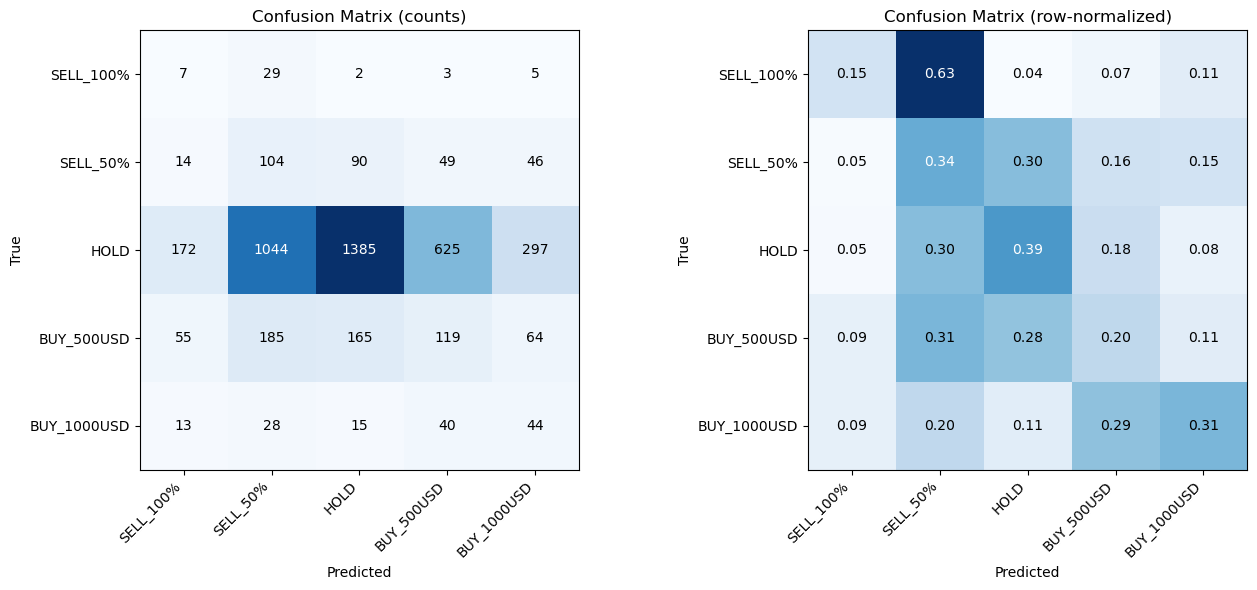

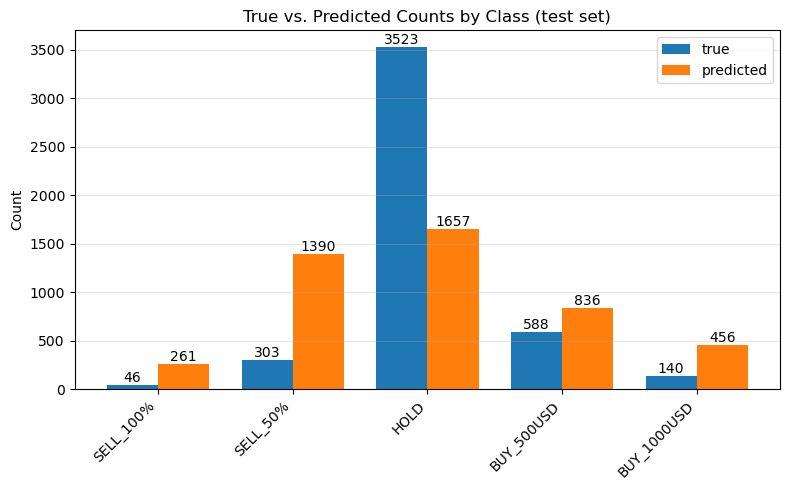

In [4]:
labels_idx = list(range(N_CLASSES))
cm = confusion_matrix(y_test, y_pred, labels=labels_idx)
cm_norm = cm.astype(float) / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

report_txt = classification_report(
    y_test, y_pred, labels=labels_idx, target_names=CLASS_NAMES, digits=4, zero_division=0
)
report_dict = classification_report(
    y_test, y_pred, labels=labels_idx, target_names=CLASS_NAMES, output_dict=True, zero_division=0
)
print("=" * 60)
print("CLASSIFICATION REPORT (test set)")
print("=" * 60)
print(report_txt)

def _plot_confusion(ax, matrix, title, fmt):
    im = ax.imshow(matrix, cmap="Blues")
    ax.set_title(title)
    ax.set_xticks(range(N_CLASSES))
    ax.set_yticks(range(N_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    thresh = matrix.max() / 2.0 if matrix.max() > 0 else 0.5
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(
                j, i, format(matrix[i, j], fmt),
                ha="center", va="center",
                color="white" if matrix[i, j] > thresh else "black",
            )
    return im

fig, (ax_cm, ax_cmn) = plt.subplots(1, 2, figsize=(14, 6))
_plot_confusion(ax_cm, cm, "Confusion Matrix (counts)", "d")
_plot_confusion(ax_cmn, cm_norm, "Confusion Matrix (row-normalized)", ".2f")
fig.subplots_adjust(bottom=0.22)
fig.tight_layout()
plt.show()

true_counts = np.bincount(y_test, minlength=N_CLASSES)
pred_counts = np.bincount(y_pred, minlength=N_CLASSES)

x = np.arange(N_CLASSES)
width = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, true_counts, width, label="true")
ax.bar(x + width / 2, pred_counts, width, label="predicted")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("Count")
ax.set_title("True vs. Predicted Counts by Class (test set)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
for xi, (tc, pc) in enumerate(zip(true_counts, pred_counts)):
    ax.text(xi - width / 2, tc, str(int(tc)), ha="center", va="bottom")
    ax.text(xi + width / 2, pc, str(int(pc)), ha="center", va="bottom")
fig.subplots_adjust(bottom=0.22)
fig.tight_layout()
plt.show()

## 5. Per-ticker analysis on the test set

Using the `ids.npy` / `dates.npy` alignment arrays from notebook 03, we break down pooled test results **by sector ticker**:
- **Per-ticker accuracy** - how well the single shared model performs on each of the 25 stocks (bar chart versus overall accuracy).
- **Latest-recommendations table** - for each ticker, the latest test window provides a BUY / HOLD / SELL recommendation with class probabilities and confidence, alongside the actual outcome.

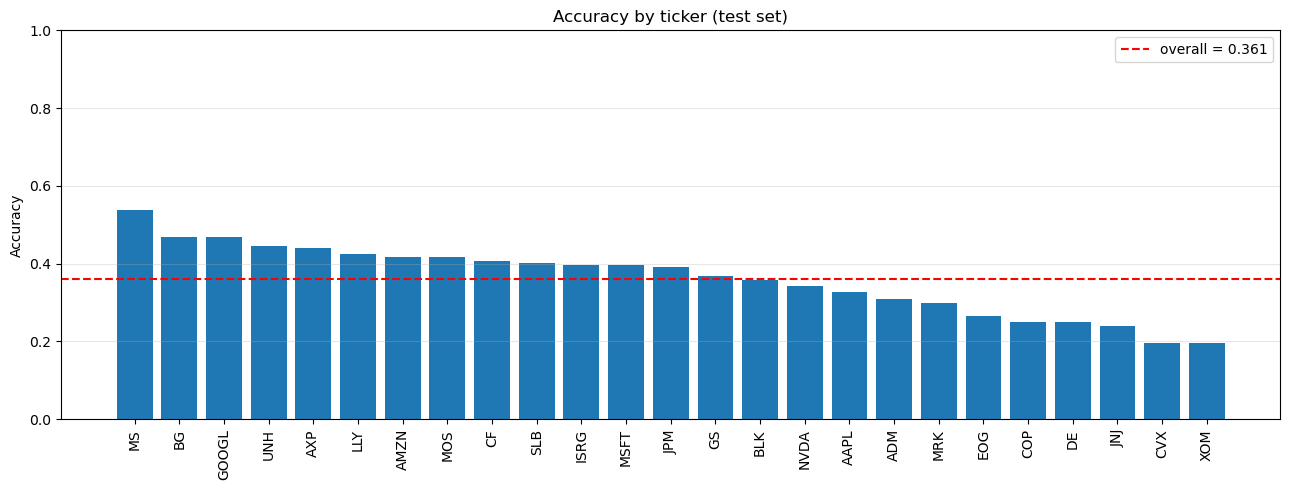

Per-ticker accuracy: mean=0.3607, min=0.1957 (XOM), max=0.5380 (MS)

Latest test-window recommendation per ticker:


,as_of_date,recommendation,actual,confidence,test_accuracy,p_SELL_100%,p_SELL_50%,p_HOLD,p_BUY_500USD,p_BUY_1000USD
ticker,,,,,,,,,,
AAPL,2026-05-14,SELL_50%,HOLD,0.4603,0.3261,0.0597,0.4603,0.3417,0.1293,0.0091
ADM,2026-05-14,BUY_500USD,HOLD,0.4305,0.3098,0.0017,0.1300,0.4033,0.4305,0.0345
AMZN,2026-05-14,BUY_500USD,HOLD,0.3518,0.4185,0.0205,0.2329,0.3346,0.3518,0.0601
AXP,2026-05-14,SELL_50%,HOLD,0.5018,0.4402,0.3079,0.5018,0.1651,0.0249,0.0003
BG,2026-05-14,BUY_1000USD,HOLD,0.4788,0.4674,0.0000,0.0096,0.1063,0.4053,0.4788
BLK,2026-05-14,BUY_500USD,SELL_50%,0.3897,0.3587,0.0140,0.1944,0.2968,0.3897,0.1051
CF,2026-05-14,HOLD,HOLD,0.4653,0.4076,0.0009,0.1418,0.4653,0.3578,0.0342
COP,2026-05-14,SELL_50%,HOLD,0.5109,0.2500,0.0712,0.5109,0.3594,0.0571,0.0014
CVX,2026-05-14,SELL_50%,HOLD,0.7092,0.1957,0.1240,0.7092,0.1561,0.0106,0.0000


In [5]:
test_ids = np.load(DATASET_DIR / "test" / "ids.npy", allow_pickle=True)
test_dates = np.load(DATASET_DIR / "test" / "dates.npy", allow_pickle=True)
assert len(test_ids) == len(y_test) == len(y_pred), "ids/labels length mismatch"

tickers_sorted = sorted(np.unique(test_ids).tolist())

# Per-ticker accuracy.
per_ticker_acc = {}
for t in tickers_sorted:
    m = test_ids == t
    per_ticker_acc[t] = float((y_pred[m] == y_test[m]).mean())

acc_items = sorted(per_ticker_acc.items(), key=lambda kv: kv[1], reverse=True)
acc_labels = [t for t, _ in acc_items]
acc_vals = [v for _, v in acc_items]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(acc_labels, acc_vals)
ax.axhline(test_acc, color="red", linestyle="--", label=f"overall = {test_acc:.3f}")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Accuracy by ticker (test set)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# Latest test-window recommendation per ticker (most recent as-of date).
rows = []
for t in tickers_sorted:
    idx = np.where(test_ids == t)[0]
    last = idx[np.argmax(test_dates[idx].astype("datetime64[D]"))]
    probs = y_prob[last]
    row = {
        "ticker": t,
        "as_of_date": str(test_dates[last]),
        "recommendation": CLASS_NAMES[y_pred[last]],
        "actual": CLASS_NAMES[int(y_test[last])],
        "confidence": round(float(probs.max()), 4),
        "test_accuracy": round(per_ticker_acc[t], 4),
    }
    for c in range(N_CLASSES):
        row[f"p_{CLASS_NAMES[c]}"] = round(float(probs[c]), 4)
    rows.append(row)

reco_df = pd.DataFrame(rows).set_index("ticker")

print(f"Per-ticker accuracy: mean={np.mean(acc_vals):.4f}, "
      f"min={min(acc_vals):.4f} ({acc_labels[-1]}), max={max(acc_vals):.4f} ({acc_labels[0]})")
print("\nLatest test-window recommendation per ticker:")
reco_df

## 6. Test analysis results for a specific ticker

Edit and rerun from here to change the ticker or restrict the date window.

- `TICKER` - any sector ticker present in the test set (e.g. `"AAPL"`).
- `DATE_START` / `DATE_END` - `None` for the full test range, or strings such as `"2026-04-01"` / `"2026-04-30"`.
- `SHOW_NON_HOLD_PLOT` - also plot the second, less cluttered chart with only non-`HOLD` signals.

In [9]:
TICKER = "AMZN"
DATE_START = "2026-01-01"  
DATE_END = "2026-05-14"  

available = sorted(np.unique(test_ids).tolist())
if TICKER not in available:
    raise ValueError(f"Ticker {TICKER!r} not in test set. Available: {available}")

## 7. Align signals with price

Keep only samples for the selected ticker, map each predicted code to its class name, and join the ticker's `Adj Close` price on the as-of date. Each test sample's date is the **last day of its 60-day window** (the decision date), so the ticker has one signal per test trading day. An optional date-range filter is applied to both the price line and the signals.

In [10]:
mask = test_ids == TICKER
sig = pd.DataFrame(
    {
        "date": pd.to_datetime(test_dates[mask]),
        "pred_code": y_pred[mask],
        "confidence": confidence[mask],
    }
)
sig["signal"] = sig["pred_code"].map(lambda c: CLASS_NAMES[c])
sig = sig.sort_values("date").reset_index(drop=True)

price_col = f"{TICKER}_Adj Close"
prices = pd.read_csv(PRICE_CSV, usecols=["Date", price_col], parse_dates=["Date"])
prices = prices.rename(columns={"Date": "date", price_col: "price"}).sort_values("date")
sig = sig.merge(prices, on="date", how="left")

start = pd.to_datetime(DATE_START) if DATE_START else sig["date"].min()
end = pd.to_datetime(DATE_END) if DATE_END else sig["date"].max()
sig_win = sig[(sig["date"] >= start) & (sig["date"] <= end)].copy()
price_win = prices[(prices["date"] >= start) & (prices["date"] <= end)].copy()
if sig_win.empty:
    raise ValueError(f"No test signals for {TICKER} in range {start.date()} .. {end.date()}")

print(f"{TICKER}: {len(sig_win)} signals from {sig_win['date'].min().date()} to {sig_win['date'].max().date()}")
print("\nSignal counts:")
print(sig_win["signal"].value_counts().reindex(ORDERED_CLASSES, fill_value=0))

AMZN: 92 signals from 2026-01-02 to 2026-05-14

Signal counts:
signal
SELL_100%       0
SELL_50%       21
HOLD           27
BUY_500USD     37
BUY_1000USD     7
Name: count, dtype: int64


## 8. Signal alignment plot (all classes)

The price is drawn as a black line; predicted signals are plotted as points on the line on the date they occurred, colored by class. The legend lists every class in the scheme (with its count in the window), including classes the model never predicted here.

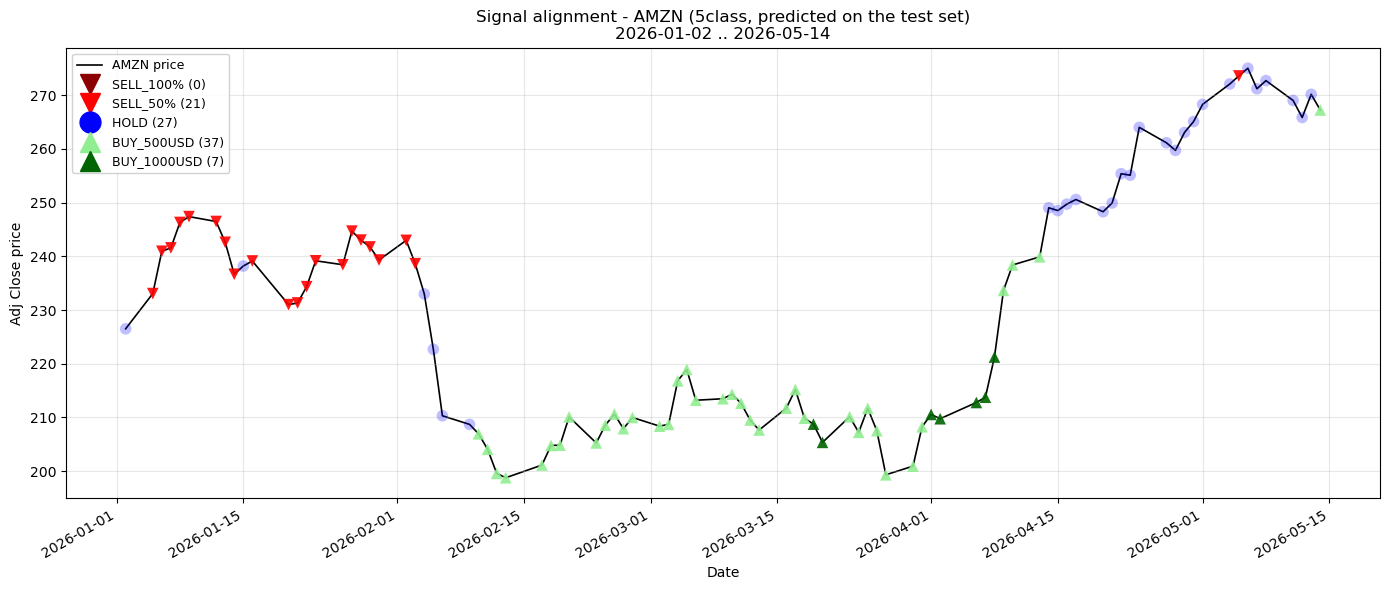

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Signal alignment - AMZN (5class, predicted on the test set)\n2026-01-02 .. 2026-05-14'}, xlabel='Date', ylabel='Adj Close price'>)

In [11]:
range_lbl = f"{sig_win['date'].min().date()} .. {sig_win['date'].max().date()}"
sp.plot_signals(
    price_win, sig_win, ORDERED_CLASSES,
    feature_metadata,
    ticker=TICKER,
    title=f"Signal alignment - {TICKER} ({LABEL_SCHEME}, predicted on the test set)\n{range_lbl}",
)